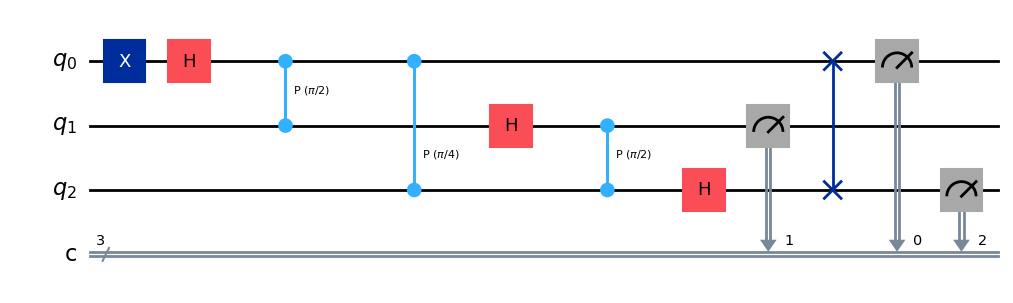

{'010': 125, '111': 135, '100': 110, '001': 134, '011': 125, '110': 111, '101': 131, '000': 129}


In [22]:
from qiskit import QuantumCircuit, transpile
from qiskit_aer import AerSimulator
from math import pi 
n = 3
qc = QuantumCircuit(n,n)
qc.x(0)
for j in range(n):
    qc.h(j)
    for k in range(j+1, n):
        qc.cp(pi / (2 ** (k - j)), k, j)
for j in range(n // 2):
    qc.swap(j, n-j-1)
qc.measure(range(n),range(n))
display(qc.draw("mpl"))
sim = AerSimulator()
qc_compile = transpile(qc, sim)
count = sim.run(qc_compile, shots=1000).result().get_counts()
print(count)

In [28]:
from math import gcd
def shor(N, a):
    print("Number : ", N)
    print("Base : ", a)
    g = gcd(a,N)
    if g > 1:
        print("Factor found directly : ", g, N // g)
        return
    r = 1
    value = a % N
    while (value != 1):
        value = (value*a) % N
        r += 1
    if r % 2 != 0:
        print("Odd order. Choose different base.")
        return
    x = pow(a, r // 2, N)
    if x == 1 or x == N-1:
        print("Cannot find factor, choose different base.")
        return
    p = gcd(x-1, N)
    q = gcd(x+1, N)
    if (p * q == N and p > 1 and q > 1):
        print("Factor : ", p, " and ",q)
    else:
        print("Try different base.")
shor(15, 2)

Number :  15
Base :  2
Factor :  3  and  5


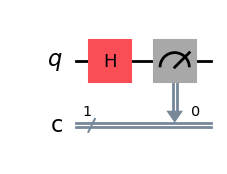

{'0': 482, '1': 518}


In [35]:
# Lab 01
from qiskit import QuantumCircuit
from qiskit_aer import AerSimulator
qc = QuantumCircuit(1,1)
qc.h(0)
qc.measure(0,0)
display(qc.draw("mpl"))
sim = AerSimulator()
count = sim.run(qc, shots = 1000).result().get_counts()
print(count)

**Theory:**

The Hadamard gate (H-gate) is a single-qubit quantum gate that creates a superposition state. It transforms the initial state |0⟩ into an equal superposition of |0⟩ and |1⟩. In Qiskit, the Hadamard gate is applied using `qc.h(0)`. The measurement operation converts the quantum state into a classical bit. When executed 1000 times, the circuit ideally produces approximately 50% zeros and 50% ones.

**Observation:**

1. The Hadamard gate creates an equal superposition of |0⟩ and |1⟩.
2. After measurement, the output contains both 0 and 1.
3. Out of 1000 shots, approximately 500 zeros and 500 ones are expected.
4. The exact counts may vary due to the probabilistic nature of quantum measurement.

**Result:**

A single-qubit quantum circuit was successfully created using the Hadamard gate in Qiskit. The simulation produced approximately equal probabilities of measuring 0 and 1.

**Conclusion:**

The experiment demonstrates that the Hadamard gate converts the initial state |0⟩ into an equal superposition of |0⟩ and |1⟩. The result verifies the fundamental principle of quantum superposition.

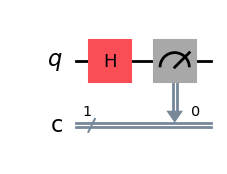

{'0': 535, '1': 465}


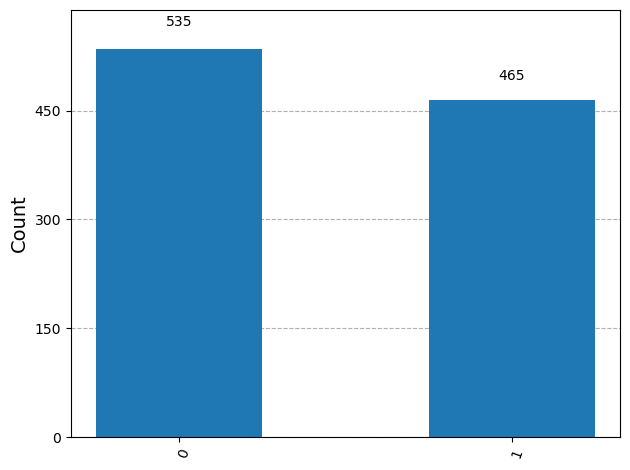

In [36]:
# Lab 02
from qiskit import QuantumCircuit
from qiskit_aer import AerSimulator
from qiskit.visualization import plot_histogram
qc = QuantumCircuit(1,1)
qc.h(0)
qc.measure(0,0)
display(qc.draw("mpl"))
sim = AerSimulator()
count = sim.run(qc, shots = 1000).result().get_counts()
print(count)
display(plot_histogram(count))

**Theory:**

Measurement is an important operation in quantum computing that converts a qubit's quantum state into a classical bit (0 or 1). In this experiment, the Hadamard gate is applied to a single qubit to create an equal superposition of |0⟩ and |1⟩. The qubit is then measured, and the circuit is executed 1000 times using the AerSimulator. The `plot_histogram()` function is used to display the measurement results graphically.

**Observation:**

1. The Hadamard gate creates an equal superposition of |0⟩ and |1⟩.
2. The measurement produces classical outputs 0 and 1.
3. The histogram displays the counts of both measurement outcomes.
4. Approximately 500 counts for each outcome are expected out of 1000 shots, although the exact counts may vary.

**Result:**

The single-qubit circuit was successfully executed, and the measurement results were displayed using a histogram. The results showed approximately equal probabilities of obtaining 0 and 1.

**Conclusion:**

The experiment demonstrates the measurement of a qubit and the graphical representation of its outcomes using a histogram in Qiskit. It verifies the probabilistic nature of quantum measurement and the superposition property of the Hadamard gate.

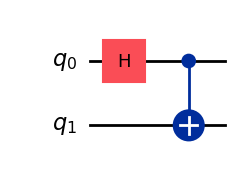

<IPython.core.display.Latex object>

In [38]:
# Lab 03
from qiskit import QuantumCircuit
from qiskit.quantum_info import Statevector
qc = QuantumCircuit(2)
qc.h(0)
qc.cx(0,1)
display(qc.draw("mpl"))
state = Statevector.from_instruction(qc)
display(state.draw("latex"))

**Theory:**

A Bell state is a maximally entangled quantum state involving two qubits. In this experiment, a two-qubit quantum circuit is created using the Hadamard (H) gate and the Controlled-NOT (CNOT) gate. First, the Hadamard gate is applied to the first qubit to create a superposition. Then, the CNOT gate is applied, using the first qubit as the control and the second qubit as the target, to generate an entangled state.

The resulting Bell state is:

|Φ⁺⟩ = (|00⟩ + |11⟩) / √2

**Observation:**

1. The Hadamard gate creates a superposition in the first qubit.
2. The CNOT gate entangles the two qubits.
3. The resulting state is an equal superposition of |00⟩ and |11⟩.
4. The state vector shows equal probability amplitudes of 1/√2 for |00⟩ and |11⟩.

**Result:**

The Bell state was successfully generated using the Hadamard and CNOT gates in Qiskit. The resulting quantum state was displayed using the Statevector function.

**Conclusion:**

The experiment demonstrates the generation of an entangled Bell state using a two-qubit quantum circuit. It verifies how quantum gates can create entanglement between qubits.

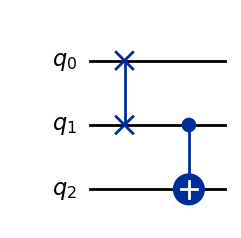

<IPython.core.display.Latex object>

In [39]:
# Lab 05
from qiskit import QuantumCircuit
from qiskit.quantum_info import Statevector
qc = QuantumCircuit(3)
qc.swap(0,1)
qc.cx(1,2)
display(qc.draw("mpl"))
state = Statevector.from_instruction(qc)
display(state.draw("latex"))

**Theory:**

A multi-qubit quantum circuit consists of two or more qubits and uses quantum gates to perform operations on them. The SWAP gate exchanges the quantum states of two qubits, while the Controlled-NOT (CNOT) gate flips the target qubit when the control qubit is in the state |1⟩. In this experiment, a three-qubit circuit is created using a SWAP gate on qubits 0 and 1, followed by a CNOT gate with qubit 1 as the control and qubit 2 as the target. The Statevector function is used to display the final quantum state.

**Observation:**

1. The SWAP gate exchanges the states of qubits 0 and 1.
2. The CNOT gate operates on qubits 1 and 2.
3. The circuit demonstrates the use of two-qubit gates in a three-qubit system.
4. The final state vector represents the quantum state after applying both gates.

**Result:**

A three-qubit quantum circuit using SWAP and CNOT gates was successfully implemented in Qiskit. The circuit diagram and final state vector were displayed.

**Conclusion:**

The experiment demonstrates the implementation of a multi-qubit circuit using SWAP and CNOT gates. It helps explain how quantum gates manipulate qubit states in a quantum computing system.

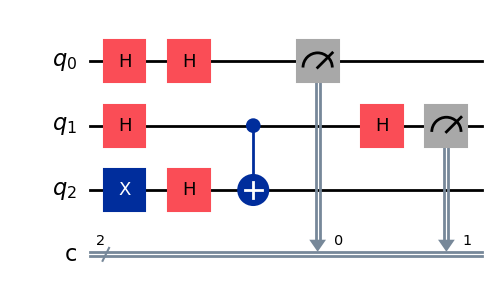

{'10': 1000}


In [44]:
# Lab 06
from qiskit import QuantumCircuit
from qiskit_aer import AerSimulator
qc = QuantumCircuit(3,2)
qc.x(2)
qc.h([0,1,2])
qc.cx(1,2)
qc.h([0,1])
qc.measure([0,1],[0,1])
display(qc.draw("mpl"))
sim = AerSimulator()
count = sim.run(qc, shots = 1000).result().get_counts()
print(count)

**Theory:**

The Deutsch-Jozsa algorithm is a quantum algorithm used to determine whether a Boolean function is constant or balanced. A constant function produces the same output for all inputs, while a balanced function produces 0 for half of the inputs and 1 for the other half. The algorithm uses Hadamard gates to create superposition, an oracle to evaluate the function, and measurement to determine the function type. It can identify whether a function is constant or balanced with a single oracle query.

**Observation:**

1. The Hadamard gates create superposition in the qubits.
2. The oracle applies the operation representing the Boolean function.
3. For a constant function, the measurement ideally produces all zeros.
4. For a balanced function, the measurement ideally produces a non-zero bit string.
5. The measurement results help identify whether the function is constant or balanced.

**Result:**

The Deutsch-Jozsa algorithm was implemented using Qiskit. The quantum circuit was executed on the AerSimulator, and the measurement counts were obtained to analyze the function.

**Conclusion:**

The experiment demonstrates the working principle of the Deutsch-Jozsa algorithm. It shows how quantum computing can distinguish between constant and balanced functions using quantum superposition and measurement.

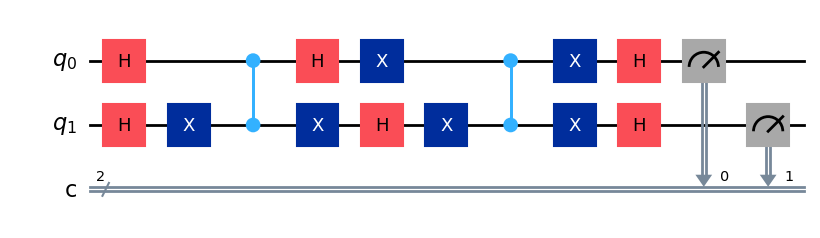

{'01': 1000}


In [47]:
# Lab 07
from qiskit import QuantumCircuit
from qiskit_aer import AerSimulator
qc = QuantumCircuit(2,2)
qc.h([0,1])
# Orcale
qc.x(1)
qc.cz(0,1)
qc.x(1)
# Diffusion
qc.h([0,1])
qc.x([0,1])
qc.cz(0,1)
qc.x([0,1])
qc.h([0,1])
qc.measure([0,1],[0,1])
display(qc.draw("mpl"))
sim = AerSimulator()
count = sim.run(qc, shots = 1000).result().get_counts()
print(count)

**Theory:**

Grover's algorithm is a quantum search algorithm used to find a marked state from an unsorted set of possible states. It uses quantum superposition, an oracle, and a diffusion operator to increase the probability of measuring the desired state. In this experiment, a two-qubit circuit is created using Hadamard gates to generate superposition. The oracle marks the target state, and the diffusion operator amplifies its probability. Finally, the measurement results are obtained using the Qiskit AerSimulator.

**Observation:**

1. Hadamard gates create a superposition of all four possible states: |00⟩, |01⟩, |10⟩, and |11⟩.
2. The oracle marks the target state |01⟩.
3. The diffusion operator amplifies the probability of measuring the marked state.
4. The circuit is executed for 1000 shots to obtain the measurement counts.
5. The marked state |01⟩ is expected to appear with the highest frequency.

**Result:**

Grover's algorithm was successfully implemented using Qiskit. The quantum circuit was executed on the AerSimulator, and the measurement counts were obtained to identify the marked state.

**Conclusion:**

The experiment demonstrates how Grover's algorithm searches for a marked state using an oracle and a diffusion operator. It shows how quantum operations can increase the probability of finding the desired solution.

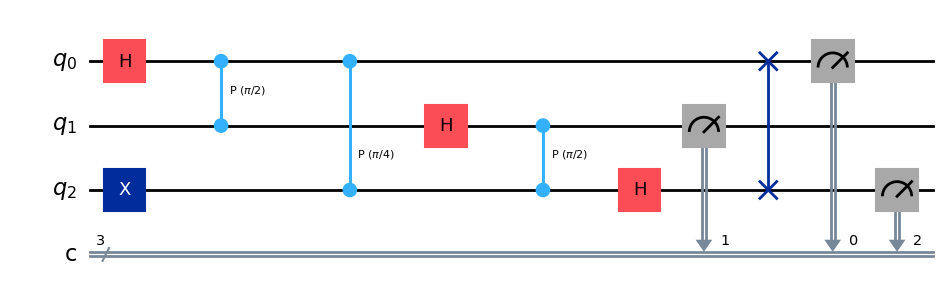

{'101': 118, '011': 135, '010': 128, '001': 126, '111': 138, '000': 117, '110': 125, '100': 113}


In [50]:
# Lab 08
# QFT
from qiskit import QuantumCircuit
from qiskit_aer import AerSimulator
from math import pi
n = 3
qc = QuantumCircuit(n,n)
qc.x(2)
for j in range(n):
    qc.h(j)
    for k in range(j+1, n):
        qc.cp(pi / (2 ** (k-j)), k, j)
for j in range (n // 2):
    qc.swap(j, n-j-1)
qc.measure(range(n), range(n))
display(qc.draw("mpl"))
sim = AerSimulator()
count = sim.run(qc, shots = 1000).result().get_counts()
print(count)

In [51]:
# Lab 08
# Shor's
from math import gcd
def shor(N, a):
    print("Number : ", N)
    print("Base : ", a)
    g = gcd(a, N)
    if g > 1:
        print("Factors found directly : ", g, N // g)
        return
    r = 1
    value = a % N
    while (value != 1):
        value = (value*a) % N
        r += 1
    if r % 2 != 0:
        print("Odd order. Choose different base.")
        return
    x = pow(a, r // 2, N)
    if (x == 1 or x == N-1):
        print("Factor can not found. Choose different base.")
        return
    p = gcd(x-1, N)
    q = gcd(x+1, N)
    if (p * q == N and p > 1 and q > 1):
        print("Factors : ", p, " and ", q)
    else:
        print("Choose different base.")
shor(15, 2)

Number :  15
Base :  2
Factors :  3  and  5


**Theory:**

The Quantum Fourier Transform (QFT) is a quantum operation that transforms a quantum state into its frequency representation. It uses Hadamard gates, controlled-phase gates, and SWAP gates to perform the transformation. QFT is an important component of several quantum algorithms, including Shor's algorithm.

Shor's algorithm is a quantum algorithm designed to factorize large integers efficiently. It uses period finding to determine the factors of a given number. In this experiment, a three-qubit circuit is used to implement QFT, and a Python function demonstrates the factorization process using the mathematical principles of Shor's algorithm. The `gcd()` function helps calculate the greatest common divisor to find the factors.

**Observation:**

1. The QFT circuit applies Hadamard and controlled-phase gates to transform the quantum state.
2. SWAP gates rearrange the qubits into the correct output order.
3. The AerSimulator executes the QFT circuit for 1000 shots and produces measurement counts.
4. Shor's algorithm calculates the order of the selected base modulo the given number.
5. For `shor(15, 2)`, the algorithm identifies the factors 3 and 5.

**Result:**

The Quantum Fourier Transform circuit was successfully implemented and simulated using Qiskit. The Shor's algorithm demonstration successfully factorized the number 15 into 3 and 5.

**Conclusion:**

The experiment demonstrates the implementation of QFT using quantum gates and the basic factorization procedure of Shor's algorithm. It illustrates the importance of quantum Fourier transforms and period finding in quantum computing.